# Building, training and scoring the network on C-MAPSS FD001

**Notebook 02.** `notebooks/README.md` says how every notebook is laid out, who it is written for, and where the code it calls actually lives. This notebook starts from exactly what notebook 01 produces.

## What this notebook is for

Notebook 01 turned the raw NASA C-MAPSS text files into examples and a sensor graph. This notebook takes those two things and builds the network that Wen et al. (2026) describe, trains it, and scores it on engines it has never seen.

## What this notebook does *not* do

- **It does not produce a result.** It trains the network once, with one random seed — the number that fixes every random choice in a run — and a single run moves when the seed changes. The numbers this project reports are averages over five seeds from `scripts/train.py`; section 6 checks that this notebook's run is the first of those five, number for number, and sets it beside their average.
- **It does not change the data.** Every preprocessing decision was made and checked in notebook 01, and this notebook repeats all of it in one call.
- **It does not train the paper's recurrent stage**, the part of its network that reads each sensor's 30 cycles in order before the sensors are combined. Step 9 builds that stage and reports what it has been measured to be worth, but it is about thirteen times slower per batch to train (timed in assumption A-26), so the network trained here uses a simpler stand-in: each sensor passes on only its most recent reading from the 30-cycle window (assumption A-07).
- **It does not explain the network's predictions.** That has its own folder, `notebooks/xai/`, with one notebook per explanation method, all explaining a network the stored five-seed run trained.

## Which published figure a result from here may be set beside

This depends on how the result was produced, and it runs through every number below.

- The network trained here has no recurrent stage, so its test error compares with the paper's **"ESTGNN w/o LSTM"** row — LSTM being the kind of recurrent network the paper uses — which is 14.93 on FD001 in its Table 11, and never with the 11.78 of the full model.
- This notebook holds 20 engines back and keeps the parameters from the pass over the data that did best on them. The paper describes neither (assumptions A-06 and A-18). Step 9 shows that for the recurrent stage this one difference decides most of what the stage appears to be worth (finding F-16).

---

## The whole notebook in one list

Notebook 01 ended at step 8, and the numbering carries on. Every step below takes the output of the step before it.

| # | Step | What goes in | What comes out |
|---|------|--------------|----------------|
| 9 | **Build** the network | the 14 x 14 sensor graph from notebook 01 | a network holding 61 729 adjustable numbers, all still random |
| 10 | **Train** it | 14 459 examples from 80 engines, each 14 sensors x 30 cycles with its label | the same network, its numbers adjusted to predict those labels, kept at the point where it did best on 20 engines it does not learn from |
| 11 | **Score** it | the 100 test examples, one per test engine | 100 predicted remaining lives, and four measures of how far they are from the test labels, each engine's remaining life capped at 125 cycles |

After the steps, section 5 points to `notebooks/graph/`, where the sensor graph is put to the test: the paper's graph set beside every sensor joined to every other and beside the sensor pairs whose readings move together most strongly, with the five-seed runs of all three read from `reports/`.

Section 3 draws the network as a picture, with every layer's size read off a real network.

One example travels through the network like this. It arrives as an array of shape `(14, 30)`: 14 sensor nodes, each with its 30-cycle window. The **temporal stage** reduces each node to one number, `(14, 1)`; by default that number is the last cycle of the window, which gives the `[batch, 14, 1]` the paper's Table 4 prints. Three **graph layers** then give each node 32, 64 and finally 32 numbers, mixing every sensor with the sensors it is joined to at each layer, which ends at `(14, 32)`. Those 14 x 32 = 448 numbers are laid end to end, reduced to 128, and reduced again to one number between 0 and 1. Multiplied by 125, that is the predicted remaining life in flight cycles.

## Where the code for this notebook is

Three folders of `src/thesis_gnn_rul_xai/` are new here: `models/` builds the network, `training/` trains it and `evaluation/` scores it. Step 10, for example, is one line here:

```python
history = train(model, prepared.train, prepared.validation, training)
```

while `train` lives in `src/thesis_gnn_rul_xai/training/run.py`, and `tests/test_training.py` calls it. Each folder's `README.md` says what its files do and why.

## 1. Background

### Where notebook 01 left off

Notebook 01 ended with three things, and this notebook starts from exactly those:

- **Examples.** One example is one engine at one moment: an array of 14 rows, one per sensor in the order of the paper's Table 3, and 30 columns, the 30 most recent flight cycles, smoothed and rescaled. Its **label** is the number of flight cycles that engine still had left at the last of those 30, capped at 125.
- **Three groups of engines.** 80 training engines, whose examples the network learns from; 20 held-back engines, which it never learns from directly; and 100 test engines, one example each, kept for the end.
- **The sensor graph.** A 14 x 14 table saying which sensors are physically related, transcribed from the paper's Table 3, with 41 connections between sensors, called **edges**.

### What a neural network is, in this project

A **neural network** here is a function. It takes one example, the 14 x 30 array, and returns one number: a predicted remaining life. What makes it different from a function written by hand is that its arithmetic contains tens of thousands of **parameters** — numbers the inputs are multiplied by and added to — and nobody chooses their values. They start out random, so a network that has just been built predicts nonsense. Step 9 builds one and counts its parameters.

**Do not confuse** a parameter with a setting. A parameter is one of those numbers inside the network, and training changes it. A setting — how many examples to use at a time, how many passes to make over the data — is chosen before training starts and does not change during it. Both notebooks keep their settings in configuration objects; the parameters exist only inside the network.

### What training does

Training repeats one small correction many thousands of times:

1. Take a **batch** of 32 training examples and their labels.
2. Run the 32 examples through the network to get 32 predictions.
3. Measure how wrong those predictions are with a single number, the **loss**. Here it is the mean squared error: each prediction's difference from its label, squared, then averaged over the 32.
4. For every parameter, work out how fast the loss would change if that one parameter alone were made slightly larger, with the 32 examples and their labels held exactly as they are. That rate of change is the parameter's **gradient**. A positive gradient means "making this parameter larger would make these 32 predictions worse". PyTorch, the library this project builds its networks with, computes the gradient of every parameter in one go.
5. Move every parameter a small step in the direction its gradient says lowers the loss. The size of the steps is set by the **learning rate** and by the **optimiser**, the rule that turns gradients into steps. The paper uses the optimiser called Adam, which scales each parameter's step using the gradients that parameter had in earlier batches; its details are not needed to follow this notebook.

Working through every training example once, batch by batch, is one **epoch**. The paper trains for 200 epochs.

**Do not confuse** the loss with the errors reported at the end. The loss is what training lowers, and it is computed on training examples. The errors of step 11 are computed afterwards, on test engines the network never saw, and they are the ones that say how good the network is.

## 2. Setup

The cell below imports everything the rest of the notebook uses. Unlike notebook 01, this one needs **PyTorch**; if it is missing, the cell stops and says how to install it. `notebooks/README.md` explains the rest of what a setup cell does, and `help(train)` in an empty cell prints what a function is for.

In [1]:
from __future__ import annotations

import json
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import HTML

# Make the package importable when the notebook is opened directly from a
# clone that has not been installed with `pip install -e .`.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

try:
    import torch
except ImportError as missing:
    raise ImportError(
        "This notebook trains a network, which needs PyTorch, and PyTorch is not "
        "installed. Install the project with its model extras,\n\n"
        '    pip install -e ".[model]"\n\n'
        "or follow section 4 of README.md. Notebook 01 does not need it."
    ) from missing

from thesis_gnn_rul_xai.config import PreprocessingConfig, load_config
from thesis_gnn_rul_xai.data.loading import read_rul_file
from thesis_gnn_rul_xai.data.pipeline import run_preprocessing
from thesis_gnn_rul_xai.docsite.figures import render_figure
from thesis_gnn_rul_xai.evaluation import prediction_error
from thesis_gnn_rul_xai.models import ESTGNN, LastCycle, LSTMStage, ModelConfig
from thesis_gnn_rul_xai.training import (
    TrainingConfig,
    evaluate_model,
    predict,
    train,
)
from thesis_gnn_rul_xai.utils.logging_setup import configure_logging

configure_logging(logging.INFO)

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

print(f"Project root: {PROJECT_ROOT}")
print(f"Python       : {sys.version.split()[0]}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"PyTorch      : {torch.__version__}   (CUDA available: {torch.cuda.is_available()})")

Project root: D:\Main\University\Thesis\Code\Thesis GNN RUL XAI
Python       : 3.11.9
NumPy        : 2.4.6
pandas       : 3.0.3
PyTorch      : 2.13.0+cpu   (CUDA available: False)


### The configuration objects

Notebook 01 collected every preprocessing setting in one object. Training needs settings of its own, so there are two objects here:

- **`PreprocessingConfig`**, read from `config/fd001.yaml` rather than typed into the cell. That file is what section 6 runs `scripts/train.py` with, so the data prepared here is the data the reported results were trained on. Its settings are the ones notebook 01 typed in, and the cell below checks that.
- **`TrainingConfig`**, the settings of step 10: how many epochs, how many examples per batch, and how the learning rate behaves.

The column beside each value says where it comes from: a table of the paper, or the numbered entry in `docs/assumptions/` where a choice the paper left open is argued.

In [2]:
config = load_config(PROJECT_ROOT / "config" / "fd001.yaml")

# The settings notebook 01 typed into its own configuration cell. The two must
# agree on everything except `notes`, a sentence of prose.
notebook_01 = PreprocessingConfig(
    subset="FD001", window_size=30, window_stride=1, rul_max=125,
    clip_test_labels=True, normalization="zscore", smoothing_alpha=0.5,
    validation_fraction=0.2, seed=42,
)
differ = sorted(key for key, value in config.to_dict().items()
                if key != "notes" and notebook_01.to_dict()[key] != value)
assert not differ, f"config/fd001.yaml and notebook 01 disagree on {differ}"

source = {
    "window_size": "Table 6", "window_stride": "A-05", "rul_max": "A-01",
    "clip_test_labels": "A-02", "normalization": "A-03", "smoothing_alpha": "A-04",
    "graph": "Table 3", "adjacency_normalization": "A-21",
    "validation_fraction": "A-06",
}
print("Preprocessing, from config/fd001.yaml:")
for key, value in config.to_dict().items():
    if key != "notes":
        print(f"  {key:26s} {str(value):10s} {source.get(key, '')}")
print("OK  The same settings notebook 01 used.\n")

# CPU, so that this run can be compared number for number with the stored
# five-seed run in section 6.
training = TrainingConfig(seed=42, device="cpu")
print("Training:")
for key, where in (("epochs", "Table 6"), ("batch_size", "Table 6"),
                   ("learning_rate", "Table 6"), ("final_learning_rate", "Table 6"),
                   ("optimizer", "Table 6"), ("loss", "Table 6"),
                   ("lr_schedule", "A-17"), ("early_stopping_patience", "A-18"),
                   ("seed", "")):
    print(f"  {key:26s} {str(getattr(training, key)):10s} {where}")

Preprocessing, from config/fd001.yaml:
  subset                     FD001      
  window_size                30         Table 6
  window_stride              1          A-05
  rul_max                    125        A-01
  clip_test_labels           True       A-02
  normalization              zscore     A-03
  smoothing_alpha            0.5        A-04
  graph                      physics    Table 3
  adjacency_normalization    row        A-21
  validation_fraction        0.2        A-06
  seed                       42         
OK  The same settings notebook 01 used.

Training:
  epochs                     200        Table 6
  batch_size                 32         Table 6
  learning_rate              0.001      Table 6
  final_learning_rate        0.0001     Table 6
  optimizer                  adam       Table 6
  loss                       mse        Table 6
  lr_schedule                step       A-17
  early_stopping_patience    20         A-18
  seed                       42        

## 3. Loading the data

As in notebook 01, this notebook runs on the real NASA measurements and nothing else. If the FD001 files are not in `data/raw/`, the next cell stops with a link to the download.

It then runs all eight steps of notebook 01 in one call, `run_preprocessing` — the call that notebook 01's section 6 checked, array for array, against its step-by-step result. Nothing new happens to the data here; if any of it is unfamiliar, notebook 01 is the place to read about it.

In [3]:
data_dir = PROJECT_ROOT / "data" / "raw"
required = [f"train_{config.subset}.txt", f"test_{config.subset}.txt", f"RUL_{config.subset}.txt"]
missing = [name for name in required if not (data_dir / name).is_file()]

if missing:
    raise FileNotFoundError(
        f"The {config.subset} files are not in {data_dir}: {missing}.\n\n"
        "This notebook runs on the real NASA measurements and nothing else. "
        "Download the 'Turbofan Engine Degradation Simulation Data Set' from\n\n"
        "    https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/\n\n"
        f"and put the three {config.subset} files into {data_dir}. If you keep the "
        "dataset elsewhere, set data_dir to that folder instead."
    )

prepared = run_preprocessing(config, data_dir=data_dir)
print()
display(prepared.summary())

17:31:54 | INFO    | thesis_gnn_rul_xai.data.loading | Loading FD001 from D:\Main\University\Thesis\Code\Thesis GNN RUL XAI\data\raw


17:31:54 | INFO    | thesis_gnn_rul_xai.data.loading | FD001 matches the expected counts, those of NASA's files (Wen et al.'s Table 5 prints the same engine counts).


17:31:54 | INFO    | thesis_gnn_rul_xai.data.loading | Loaded FD001: 20631 training rows over 100 engines, 13096 test rows over 100 engines.


17:31:54 | WARNING | thesis_gnn_rul_xai.data.pipeline | The paper keeps sensor(s) ['P15'], but in this data they carry no usable variation. They are kept anyway, because the adjacency matrix is defined over the paper's fixed 14-sensor set. Report this observation rather than silently changing the selection.


17:31:54 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


17:31:54 | INFO    | thesis_gnn_rul_xai.data.smoothing | Applied exponentially weighted moving average (alpha=0.500) to 14 columns across 100 engines.


... (4 outputs left out)

17:31:54 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 17731 window(s) of shape (14, 30) from 100 engine(s).


17:31:54 | INFO    | thesis_gnn_rul_xai.data.windowing | Built 100 window(s) of shape (14, 30) from 100 engine(s).


17:31:54 | INFO    | thesis_gnn_rul_xai.data.pipeline | Preprocessing complete: 14459 training, 3272 validation, 100 test example(s).


,examples,engines,feature_shape,target_min,target_max
split,,,,,
train,14459,80,"(14, 30)",0.0,125.0
validation,3272,20,"(14, 30)",0.0,125.0
test,100,100,"(14, 30)",7.0,125.0


**Check.** Three things must hold before anything below means anything, and notebook 01 established all three:

- the feature axis has 14 entries, one per graph node, in the order of the paper's Table 3;
- no engine appears both among the training engines and among the 20 held back;
- each test engine contributes exactly one example, taken at the single moment its official label describes.

In [4]:
assert prepared.train.features.shape[1] == 14
assert set(prepared.train.units.tolist()).isdisjoint(prepared.validation.units.tolist())
assert len(prepared.test) == len(np.unique(prepared.test.units))

print(f"OK  {len(prepared.train):>6} training windows from {len(np.unique(prepared.train.units)):>3} engines")
if len(prepared.validation):
    print(f"OK  {len(prepared.validation):>6} held-back windows from {len(np.unique(prepared.validation.units)):>3} engines, none of them training engines")
else:
    print("OK       0 held-back windows: this configuration holds nothing back (A-06),")
    print("         so every engine trains and no epoch is chosen over any other.")
print(f"OK  {len(prepared.test):>6} test windows from {len(np.unique(prepared.test.units)):>3} engines, one each")
print()
print(f"One example has shape {prepared.train.features.shape[1:]}: "
      f"14 sensors, {prepared.train.features.shape[2]} cycles each.")
print("The pipeline hands over the whole window. How many of those numbers a")
print("sensor node carries into the graph layers is decided by the model, in step 9.")

OK   14459 training windows from  80 engines
OK    3272 held-back windows from  20 engines, none of them training engines
OK     100 test windows from 100 engines, one each

One example has shape (14, 30): 14 sensors, 30 cycles each.
The pipeline hands over the whole window. How many of those numbers a
sensor node carries into the graph layers is decided by the model, in step 9.


### The whole network in one picture

The list above names the three steps. The figure below draws what steps 9 and 10 work on — the network itself — and adds what a list cannot show: the shape the data has as it leaves each layer, and how many adjustable numbers each layer holds.

As with notebook 01's map, none of those numbers is written down by hand. The figure builds a real network and reads them off it, so it cannot fall out of step with the code. It is produced by `draw_architecture()` in `src/thesis_gnn_rul_xai/docsite/figures.py`, the same file that draws notebook 01's map and every diagram on the project's documentation website.

Three things to look for while reading it:

- **The first box, Input, holds no adjustable numbers.** It is Table 4's Input row with the temporal stage inside it: where each sensor's 30 cycles become the one number the rest of the network sees. By default the stage does that by keeping the last cycle, which is why the box's second line reads w/o LSTM, the paper's name for its network without the recurrent stage. Step 9 explains that choice, and builds the paper's own version, which does learn.
- **The three graph layers are the only place the sensor graph is used.** Everything before them treats each sensor on its own; everything after them works on sensors that have already been mixed with their neighbours.
- **Almost all of the adjustable numbers sit in one layer, FC-1** — 57 472 of the 61 729. It is a fully connected layer: every one of the 448 numbers leaving the graph layers is joined to every one of its 128 outputs. The three graph layers, which carry the paper's engineering knowledge, hold 4 128 between them.

In [5]:
# Built from a real network, so the sizes below are the ones step 9 checks
# against the paper's Table 4.
#
# It is handed over as HTML rather than as an SVG display object, for the
# reason notebook 01 gives: the documentation site renders notebooks with
# nbconvert, which drops an image/svg+xml output and keeps a text/html one.
#
# Building that network logs a line, which is quietened here and here only.
package_log = logging.getLogger("thesis_gnn_rul_xai")
package_log.setLevel(logging.ERROR)
try:
    display(HTML(render_figure("architecture")))
finally:
    package_log.setLevel(logging.INFO)

## 4. The three steps

Each of the three subsections below is one step, numbered on from notebook 01's eight, and each takes the output of the one before it. Every step is written the same way: what it does, why it is necessary, and a check confirming it did what was intended.

One thing worth saying before starting, because it plays the part here that the order of steps 5, 6 and 7 played in notebook 01. **Three groups of engines are used, and each may be used for one purpose only.**

- The **80 training engines** are the only ones whose labels change the network's parameters, in step 10.
- The **20 held-back engines** never change the parameters directly. But after every epoch the network predicts them, and the epoch that did best on them is the one kept. So they do shape the network, and that is why their error is not a fair score of it (assumption A-06).
- The **100 test engines** are touched once, in step 11, after training has finished. Nothing in steps 9 and 10 reads them. If a choice were made by looking at their error, the score in step 11 would no longer be an honest estimate of anything.

This project has not kept to the last rule everywhere. The independent audit of 2026-09-08 (`docs/audits/AUDIT_2026-09-08_scientific_validity.md`) reports that every comparison between configurations since 2026-08-29 was decided on test error. Set beside their held-back errors on 2026-10-02, the choice of z-score scaling holds for this network and the choice of row rescaling does not: on held-back error the two rescalings are a tie (assumptions A-03 and A-21; `docs/audits/AUDIT_2026-09-08_response.md` answers each of the audit's items). The comparison of sensor graphs in `notebooks/graph/04_comparison_fd001.ipynb` shows the held-back error beside the test error.

### Step 9 — Build the network

#### What a graph convolution does

Each of the three graph layers does two things to every sensor at once. First it **mixes**: each sensor's numbers are replaced by the average of its own numbers and those of the sensors it is joined to. Then it **transforms**: every sensor's averaged numbers are multiplied by the same learned table, which turns `F` numbers per sensor into `F'`. The paper writes both as one line per layer. Its Equation 8, the first layer, is $H^{(1)} = \mathrm{ReLU}\left(\tilde{A} X W^{(1)}\right)$: $\tilde{A}$, A with a tilde, is the rescaled sensor graph, and $X$ is what the sensors carry in (the sentence after it, defining the graph, prints a plain $A$). This notebook writes the rescaled graph $\hat{A}$, A with a hat, as `notebooks/graph/` does, and calls what enters any of the three layers $H$:

$$H' = \mathrm{ReLU}\left(\hat{A} \, H \, W\right)$$

- $H$ is what enters the layer, an array of shape `(14, F)`: one row per sensor, `F` numbers in each row. For the first layer `F` is 1.
- $\hat{A}$ is the sensor graph from notebook 01, shape `(14, 14)`, with every sensor also joined to itself and each row then divided by its own total. Every row adds up to 1, so multiplying by it averages each sensor with its neighbours. The paper does not print which of two such formulas it uses; dividing each row by its total is this project's choice (assumption A-21). $\hat{A}$ is **not learned**: it is the engineering knowledge the paper builds in.
- $W$ is the layer's learned table, shape `(F, F')`. The same table serves all 14 sensors, which is why a graph layer holds few parameters: the first layer's is `1 x 32`, 32 numbers in all.
- $\mathrm{ReLU}$ replaces every negative number with zero and leaves the rest alone. Without it the three layers would compute $\hat{A}^3 H W^{(1)} W^{(2)} W^{(3)}$, which is one layer with one larger table, and nothing would be gained by having three.
- $H'$ is what leaves, shape `(14, F')`, and it becomes the next layer's $H$.

Because each sensor's new numbers are built from its neighbours' old ones, the second layer reaches the neighbours of neighbours: the numbers it averages already carry what those sensors' own neighbours held. Three layers reach three edges away and no further, a limit `notebooks/graph/01_physics_fd001.ipynb` tests.

(Corrected 2026-10-03: this said the paper's Equation 8 is the general line above, with $\hat{A}$. The paper prints $\tilde{A}$, and writes the first layer's input $X$; checked on page 6 of the paper, rendered at ten times its size. Found by comparing this cell with `notebooks/graph/01_physics_fd001.ipynb`, which already quoted the equation as printed.)

The cell below does the mixing half by hand, on the first test engine's last cycle — one number per sensor, which is exactly what the first graph layer receives.

In [6]:
order = list(prepared.sensor_symbols)
a_hat = prepared.adjacency_normalized              # NumPy array, shape (14, 14)
h = prepared.test.features[0, :, -1]              # NumPy array, shape (14,)

sensor = "P15"
row = order.index(sensor)
joined = [order[j] for j in np.flatnonzero(a_hat[row])]
print(f"{sensor} is joined to {len(joined)} sensors, itself included: {joined}")
print(f"Its row of the normalised graph gives each of them {a_hat[row, row]:.4f} "
      f"= 1/{len(joined)}, and 0 to the rest.\n")
for name in joined:
    print(f"  {name:8s} {h[order.index(name)]:+.4f}")

by_hand = sum(h[order.index(name)] for name in joined) / len(joined)
by_matrix = (a_hat @ h)[row]
print(f"\n  their average, by hand        {by_hand:+.4f}")
print(f"  {sensor}'s entry of A_hat @ H     {by_matrix:+.4f}")
assert abs(by_hand - by_matrix) < 1e-6
print("\nOK  Multiplying by the normalised graph averages each sensor with its neighbours.")

P15 is joined to 5 sensors, itself included: ['T24', 'P15', 'Nf', 'NRf', 'BPR']
Its row of the normalised graph gives each of them 0.2000 = 1/5, and 0 to the rest.

  T24      -0.4272
  P15      +0.2280
  Nf       -0.2107
  NRf      -0.3687
  BPR      -0.9152

  their average, by hand        -0.3388
  P15's entry of A_hat @ H     -0.3388

OK  Multiplying by the normalised graph averages each sensor with its neighbours.


#### The architecture

Table 4 of the paper gives the size of every layer after the temporal stage, so none of those is a guess. The cell below prints the network in the same form as that table, one row per row of Table 4, for checking side by side.

Table 4 has no row for the temporal stage, the part that turns each sensor's 30 cycles into one number: the paper's table begins at its Input row, one number per sensor, where that stage has already finished. What the stage hands on is exactly that row, so the stage is folded into it. `B` is the number of windows in a batch, Table 4's `batch size`. The Input row's `in` is the window the stage receives, `(B, 14, 30)`, where Table 4, which starts after the stage, prints `[batch size,14,1]`; its `out` is the `(B, 14, 1)` Table 4 prints; its `parameters` count what the stage learns; and its `from` names the stage when the stage learns anything. The stage used here keeps each sensor's last cycle and learns nothing, so `parameters` is 0 and `from` is empty; it is this project's stand-in for the paper's stage (assumption A-07), not something Table 4 prints. Every row below the Input row has Table 4's shapes and activation, and FC-1 and FC-2 also count the offsets Equations 12 and 13 print, 128 and 1, which Table 4 does not list. The part after the check explains the stage.

(Changed 2026-10-03: until then this table had a row of its own for the stage, "Temporal", above the Input row, and the two rows described the same array. The author decided on 2026-10-02 to show them as one row, as the playground and the figure above already did.)

(Corrected 2026-10-03: the comparison of the two stages after the check printed "Every row below it is Table 4, unchanged". Table 4's Parameters column lists only the weight matrices, so FC-1's 57,472 and FC-2's 129 include two offsets it does not print. Found by a review of the change above.)

In [7]:
model = ESTGNN(
    prepared.adjacency_normalized,
    temporal=LastCycle(config.window_size),
    rul_max=config.rul_max,
)
print()
display(pd.DataFrame(model.layer_summary()).fillna(""))   # only the Input row has a `from`
print(f"Trainable parameters: {model.count_parameters():,}")

17:31:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


,layer,type,from,in,out,parameters,activation
0,Input,Node features,,"(B, 14, 30)","(B, 14, 1)",0,-
1,GCN-1,GCN,,"(B, 14, 1)","(B, 14, 32)",32,ReLU
2,GCN-2,GCN,,"(B, 14, 32)","(B, 14, 64)",2048,ReLU
3,GCN-3,GCN,,"(B, 14, 64)","(B, 14, 32)",2048,ReLU
4,Flatten,Tensor reshape,,"(B, 14, 32)","(B, 448)",0,-
5,FC-1,Fully connected,,"(B, 448)","(B, 128)",57472,ReLU
6,FC-2,Fully connected,,"(B, 128)","(B, 1)",129,Sigmoid


Trainable parameters: 61,729


**Check.** With one number per sensor reaching the first graph layer — the shape Table 4 actually prints — the parameter count must match the weight matrices the paper lists: $W^{(1)}\in\mathbb{R}^{1\times32}$, $W^{(2)}\in\mathbb{R}^{32\times64}$, $W^{(3)}\in\mathbb{R}^{64\times32}$, $W_{fc1}\in\mathbb{R}^{448\times128}$, $W_{fc2}\in\mathbb{R}^{128\times1}$, plus one offset per output of the two fully connected layers, which the paper's Equations 12 and 13 print as $b_{fc1}$ and $b_{fc2}$ and Equations 8 to 10 do not print for the graph layers (assumption A-12). The Input row, where Table 4 prints a dash, holds none.

In [8]:
table4 = ESTGNN(prepared.adjacency_normalized,
                temporal=LastCycle(config.window_size),
                rul_max=config.rul_max)
# The five weight matrices Table 4 prints, then the offsets Equations 12 and 13
# print for the two dense layers, one per output.
weights = 1*32 + 32*64 + 64*32 + 448*128 + 128*1
offsets = 128 + 1
expected = weights + offsets
assert (weights, offsets, expected) == (61_600, 129, 61_729)
assert table4.count_parameters() == expected
assert model.count_parameters() == expected
print(f"OK  Table 4's five weight matrices hold {weights:,} numbers, and the offsets")
print(f"    Equations 12 and 13 print for the two dense layers add {offsets}: {expected:,} in all.")
print(f"    Ours has {model.count_parameters():,} - the same number, because each sensor node")
print(f"    carries one value, which is the [batch, 14, 1] input Table 4 prints (assumption A-07).")

17:31:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


OK  Table 4's five weight matrices hold 61,600 numbers, and the offsets
    Equations 12 and 13 print for the two dense layers add 129: 61,729 in all.
    Ours has 61,729 - the same number, because each sensor node
    carries one value, which is the [batch, 14, 1] input Table 4 prints (assumption A-07).


#### The stage in front of the graph layers

Table 4 begins at `Input | Node features | [batch size,14,1]`. That is where the
paper's own architecture table starts, and it is worth noticing what sits
*before* it: nothing. The recurrent stage the paper describes in Section 2.2 has
**no row in Table 4 at all**.

So the network has three parts, not two, and the paper prints only the last two:

```
window of 30 cycles  ->  temporal stage  ->  graph layers  ->  dense layers
   (14, 30)                 (14, 1)            (14, 32)          one number
```

The pipeline hands over all thirty cycles. **What a sensor node carries is a
question about the model**, so it is answered in the model, by a named stage in
`models/temporal/`. Two of them matter here:

- **`LastCycle`** keeps the most recent reading and drops the other 29. It
  learns nothing. It stands in for the paper's recurrent stage (assumption
  A-07), and it is what every result in this project before 2026-09-09 was
  produced with.
- **`LSTMStage`** is the paper's own stage: **fourteen dedicated recurrent
  networks, one per sensor**. A recurrent network reads a sequence one step at
  a time, carrying numbers forward from each cycle to the next, so it can use
  all thirty cycles rather than the last one; an LSTM (long short-term memory)
  is a kind of recurrent network. Section 2.2 of the paper states the
  one-per-sensor arrangement four times — *"Each sensor s ∈ {1, 2, …, n} is
  associated with a dedicated LSTM network"*, with Equation 7 giving each
  sensor its own hidden state, the numbers carried from one cycle to the next.
  That part is a citation, not a choice. What the paper never states is the
  size, the depth, or how the network's output becomes the one number Table 4
  wants, so those are this project's choices (assumption A-26). Nor does it
  give the numbers the network starts from before training; the stage keeps
  PyTorch's own (assumption A-34).

Why this arrangement rather than letting the pipeline decide: with the width
read off the data, deleting one line of preprocessing silently made the first
graph weight matrix `(30, 32)` instead of `(1, 32)`. That happened on
2026-08-28, the model scored *better*, and two of this project's three
configuration comparisons reversed direction before anyone noticed the
architecture had changed. The full story is in `docs/assumptions/A-07.md`
(assumption A-07). The model now refuses
to build a stage that widens a node without learning anything across the
cycles, unless the caller asks for it in words.

In [9]:
# The same graph, the same everything else, two different temporal stages.
stand_in = ESTGNN(prepared.adjacency_normalized,
                  temporal=LastCycle(config.window_size),
                  rul_max=config.rul_max)
paper_stage = ESTGNN(prepared.adjacency_normalized,
                     temporal=LSTMStage(window_size=config.window_size,
                                        n_nodes=14, hidden_size=32),
                     rul_max=config.rul_max)

rows = []
for name, built in (("last_cycle (A-07 stand-in)", stand_in),
                    ("lstm, hidden 32 (the paper's)", paper_stage)):
    stage_size = sum(p.numel() for p in built.temporal.parameters())
    rows.append({
        "temporal stage": name,
        "numbers per node": built.in_features,
        "stage parameters": stage_size,
        "whole model": built.count_parameters(),
    })
display(pd.DataFrame(rows))

print("Both give the graph layers ONE number per sensor, so W(1) stays "
      "1 x 32 and")
print("Table 4 is untouched either way. What changes is where that number "
      "comes from.")
print()
print(f"The paper's stage costs "
      f"{paper_stage.count_parameters() - stand_in.count_parameters():,} extra "
      f"parameters,")
print(f"which brings the model to "
      f"{paper_stage.count_parameters() / stand_in.count_parameters():.2f} "
      f"times its previous size.")

paper_rows = paper_stage.layer_summary()
display(pd.DataFrame(paper_rows).fillna(""))
assert paper_rows[1:] == stand_in.layer_summary()[1:]
input_row = paper_rows[0]
print(f"The Input row takes the {input_row['in']} window and hands on the "
      f"{input_row['out']} Table 4 prints.")
print(f"It counts the {input_row['parameters']:,} numbers the stage learns, and its "
      f"'from' names the stage: {input_row['from']}.")
print("Every row below it is the same as for the stand-in: Table 4's shapes and "
      "activations,")
print("with FC-1 and FC-2 also counting the offsets of Equations 12 and 13.")

17:31:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


17:31:54 | INFO    | thesis_gnn_rul_xai.models.temporal | Built LSTM temporal stage: 14 cell(s) of hidden size 32 over a 30-cycle window, projected to 1 number(s) per sensor. 62753 parameters.


17:31:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 124482 trainable parameters.


,temporal stage,numbers per node,stage parameters,whole model
0,last_cycle (A-07 stand-in),1,0,61729
1,"lstm, hidden 32 (the paper's)",1,62753,124482


Both give the graph layers ONE number per sensor, so W(1) stays 1 x 32 and
Table 4 is untouched either way. What changes is where that number comes from.

The paper's stage costs 62,753 extra parameters,
which brings the model to 2.02 times its previous size.


,layer,type,from,in,out,parameters,activation
0,Input,Node features,LSTM,"(B, 14, 30)","(B, 14, 1)",62753,-
1,GCN-1,GCN,,"(B, 14, 1)","(B, 14, 32)",32,ReLU
2,GCN-2,GCN,,"(B, 14, 32)","(B, 14, 64)",2048,ReLU
3,GCN-3,GCN,,"(B, 14, 64)","(B, 14, 32)",2048,ReLU
4,Flatten,Tensor reshape,,"(B, 14, 32)","(B, 448)",0,-
5,FC-1,Fully connected,,"(B, 448)","(B, 128)",57472,ReLU
6,FC-2,Fully connected,,"(B, 128)","(B, 1)",129,Sigmoid


The Input row takes the (B, 14, 30) window and hands on the (B, 14, 1) Table 4 prints.
It counts the 62,753 numbers the stage learns, and its 'from' names the stage: LSTM.
Every row below it is the same as for the stand-in: Table 4's shapes and activations,
with FC-1 and FC-2 also counting the offsets of Equations 12 and 13.


#### What the stage is worth, measured — and why that has two answers

The full comparison is written up in `docs/findings/F-16.md` (finding F-16);
the runs are in `reports/`. Five seeds each, everything else identical, on the real FD001 test
engines, under two training procedures:

| Training procedure | `last_cycle` | `lstm`, hidden 32 | LSTM worth | paired *p* |
|---|---|---|---|---|
| **the paper's**: nothing held back, 200 epochs, final parameters | 16.818 ± 0.157 | 16.052 ± 0.975 | **+0.77** | **0.117** |
| this project's: 20 % held back, best epoch's parameters kept | 16.496 ± 0.415 | 13.307 ± 0.532 | +3.19 | 0.0009 |
| *the paper's Table 11, FD001* | *14.93* | *11.78* | *+3.15* | — |

The two rows disagree, and the disagreement is the finding.

**With this project's procedure the stage looks worth 3.19 cycles**, close to
the 3.15 the paper's Table 11 prints. **With the paper's own procedure it is
worth 0.77, and five seeds cannot tell that apart from nothing.** Table 6 of
the paper states 200 epochs and it describes no held-back engines, so the
first row is the one that follows the paper.

What separates them is keeping the best epoch's parameters. It is worth +2.75
cycles to the recurrent model (*p* = 0.004) and only +0.32 to the stand-in
(*p* = 0.23). The recurrent model has twice the parameters, reaches its lowest
error on the held-back engines between epochs 9 and 21, and gets much worse
over the rest of the 200; the smaller model barely moves. So choosing the epoch
is not a neutral detail here — it accounts for most of what the stage appeared
to be worth.

Three cautions belong with that table:

- **It does not show the paper selected epochs without saying so.** That
  would explain the agreement with Table 11, but the paper does not say, so it
  stays a suspicion.
- **A paired *p* across seeds tests only whether a difference is an artefact of
  the seed.** The five seeds share one test set of 100 engines, so none
  of these numbers is uncertainty over engines, a point the audit of
  2026-09-08 makes.
- **The over-training was first inferred, and has since been observed.** The
  recurrent runs first measured for the table did not save the error after
  every epoch, so it was read from where the best epochs fall and how much
  worse the final parameters are. Two later runs saved it (finding F-16).
  The first, on 2026-09-14 (at `f386291-dirty`), trained this project's
  recurrent row again and gave the same five test errors to every stored
  digit and the same kept epochs, so its curves are that row's: on every seed
  the training loss was lower, and the error on the held-back engines higher,
  twenty epochs after the kept one, where early stopping ended the run, at
  epoch 41 at the latest. The second, on 2026-10-03, trained the same
  configuration from a clean commit (`19dceb5`) for all 200 epochs, on the
  graphics card with PyTorch 2.5.1. It does not reproduce the table seed for
  seed (test error 13.209 ± 0.708 cycles against 13.307 ± 0.532), which
  `docs/findings/F-16.md` puts down to the graphics card and that version of
  PyTorch computing slightly differently (finding F-16). What it shows is how
  this configuration's curves run to the end: on every seed the training loss
  at epoch 200 is far below its value at the kept epoch, while the error on
  the held-back engines is 2.78 to 4.52 cycles above it.

(Corrected 2026-10-03: the last caution said the over-training is inferred and
not observed, and that re-running would settle it. Both re-runs had been made,
and finding F-16 records them. Found by checking this notebook's text against
the log when it was executed again; a review the same day added the first
re-run, and that the second was trained on the graphics card and does not
reproduce the table seed for seed.)

Because the stage is about thirteen times slower per batch to train
(assumption A-26), the rest of this notebook uses `last_cycle`. Pass `--temporal lstm` to
`scripts/train.py` to train the other one.

### Step 10 — Train

Table 6 of the paper gives the settings printed in section 2: the Adam optimiser, 200 epochs, 32 examples per batch, a learning rate falling from $10^{-3}$ to $10^{-4}$, and mean squared error as the loss. Two things it does not give are recorded as choices rather than hidden in the code: **how** the learning rate travels between those two values — one drop, by a factor of ten, at the halfway epoch (assumption A-17) — and when to stop early (assumption A-18).

**Where this differs from the paper.** `config/fd001.yaml` holds 20 engines back, and that switches on two things the paper does not describe. After every epoch the network predicts the held-back engines; if 20 epochs pass without that error improving, training stops early (assumption A-18); and however it ends, training restores the parameters from the epoch that did best (assumption A-06). So the 200 epochs of Table 6 are a limit here rather than what runs, and the network you get back is the best epoch's, not the last one's. For this network that whole arrangement is worth 0.32 cycles, which five seeds cannot tell apart from nothing (A-06); step 9 showed it is worth far more to the recurrent one.

#### Why the targets are divided by 125

The network ends in a **sigmoid**, a function that squeezes any number into the range between 0 and 1. A label measured in cycles could never be reached by such a layer. Targets are therefore divided by `rul_max` for training and predictions multiplied back, a step the paper implies rather than prints, and one forced rather than chosen (assumption A-13).

It has one consequence worth stating: **the model cannot predict a remaining life above 125 for any input whatsoever.** That is why the test labels are capped at 125 as well (assumption A-02), and step 11 checks it.

In [10]:
torch.manual_seed(training.seed)
model = ESTGNN(
    prepared.adjacency_normalized,
    temporal=LastCycle(config.window_size),
    rul_max=config.rul_max,
)
history = train(model, prepared.train, prepared.validation, training)
print()
print(history.summary())

17:31:54 | INFO    | thesis_gnn_rul_xai.models.estgnn | Built ESTGNN: 14 node(s), 1 feature(s) per node, graph layers [32, 64, 32], flatten to 448, dense 128 -> 1. 61729 trainable parameters.


17:31:57 | INFO    | thesis_gnn_rul_xai.training.run | Training for up to 200 epoch(s) on 14459 window(s), batch size 32, learning rate 1.0e-03 -> 1.0e-04 (step schedule).


17:31:59 | INFO    | thesis_gnn_rul_xai.training.run | epoch    1/200  train 0.03644  validation 22.188 cycles  lr 1.00e-03


17:32:10 | INFO    | thesis_gnn_rul_xai.training.run | epoch   10/200  train 0.02825  validation 21.298 cycles  lr 1.00e-03


17:32:32 | INFO    | thesis_gnn_rul_xai.training.run | epoch   20/200  train 0.02801  validation 21.177 cycles  lr 1.00e-03


17:32:51 | INFO    | thesis_gnn_rul_xai.training.run | epoch   30/200  train 0.02775  validation 21.215 cycles  lr 1.00e-03


... (3 outputs left out)

17:35:11 | INFO    | thesis_gnn_rul_xai.training.run | epoch   70/200  train 0.02710  validation 21.248 cycles  lr 1.00e-03


17:35:15 | INFO    | thesis_gnn_rul_xai.training.run | Stopping at epoch 71: the validation error has not improved for 20 epoch(s). Restoring the weights from epoch 51.


17:35:15 | INFO    | thesis_gnn_rul_xai.training.run | Trained for 71 epoch(s) in 197.2s, ending on early stopping. At its best, epoch 51, the model was out by 20.821 flight cycles on the engines held back from training. It holds the weights from that epoch.



Trained for 71 epoch(s) in 197.2s, ending on early stopping. At its best, epoch 51, the model was out by 20.821 flight cycles on the engines held back from training. It holds the weights from that epoch.


#### The learning curve

The left panel is the training loss after each epoch. It is on the scale the network sees, not in flight cycles: the targets were divided by 125 on the way in. The right panel is the error on the 20 held-back engines after each epoch, in flight cycles, with the epoch whose parameters were kept marked.

A falling training loss says only that the network is fitting the engines it was shown. The right panel is what says whether that fit carries over to engines it was not shown — and it is also what chose the parameters, which is why the score comes from the test engines in step 11 and not from this panel.

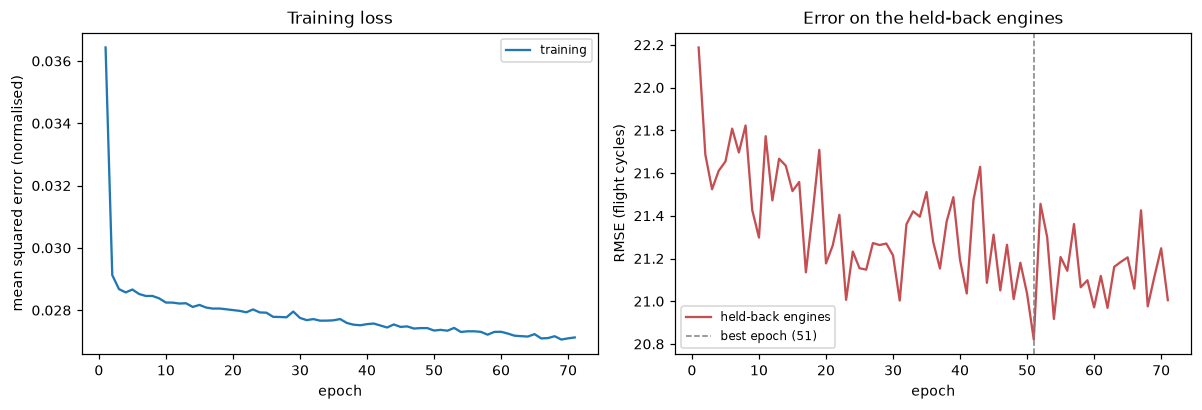

In [11]:
# The second panel exists only when engines were held back. With a
# configuration that holds nothing back there is no per-epoch error to draw.
held_back = "validation_rmse_cycles" in history.epochs.columns

fig, axes = plt.subplots(1, 2 if held_back else 1,
                         figsize=(11 if held_back else 6, 3.8), squeeze=False)
axes = axes[0]

axes[0].plot(history.epochs["epoch"], history.epochs["train_loss"], label="training")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("mean squared error (normalised)")
axes[0].set_title("Training loss"); axes[0].legend(fontsize=8)

if held_back:
    axes[1].plot(history.epochs["epoch"], history.epochs["validation_rmse_cycles"],
                 color="#C44E52", label="held-back engines")
    axes[1].axvline(history.best_epoch, color="grey", linestyle="--", linewidth=1,
                    label=f"best epoch ({history.best_epoch})")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("RMSE (flight cycles)")
    axes[1].set_title("Error on the held-back engines"); axes[1].legend(fontsize=8)

fig.tight_layout(); plt.show()

**A warning about the held-back error.** It is *not* comparable with the test error in step 11, and the gap between the two means nothing about the model. The two weight their engines completely differently: the held-back set keeps every window of its 20 engines, so one long-lived engine contributing 240 windows can move the figure, while each of the 100 test engines contributes exactly one window and is worth exactly one per cent.

Error on held-back engines is the right signal for deciding when to stop training and for comparing two settings, because both are relative judgements against a fixed set. It is the wrong number to publish (assumption A-06).

**Check.** The network that came back is the best epoch's, not the last epoch's. Predicting the held-back engines again must give exactly the error recorded for that epoch.

In [12]:
if len(prepared.validation):
    again = evaluate_model(model, prepared.validation)["rmse"]
    print(f"Epochs run: {len(history.epochs)}. Best: epoch {history.best_epoch}, "
          f"at {history.best_validation_rmse:.6f} cycles on the held-back engines.")
    print(f"The returned network, predicting them again now:  {again:.6f} cycles.")
    assert abs(again - history.best_validation_rmse) < 1e-6
    print("\nOK  The parameters kept are the best epoch's.")
else:
    print("Nothing was held back, so every epoch ran and the last one's parameters were kept.")

Epochs run: 71. Best: epoch 51, at 20.820957 cycles on the held-back engines.
The returned network, predicting them again now:  20.820957 cycles.

OK  The parameters kept are the best epoch's.


### Step 11 — Score

Four measures, all defined in Section 3.3 of the paper, all computed over the 100 test engines from one prediction each. With `d = ŷ - y` the error in cycles, where `ŷ` is the prediction and `y` the test engine's label: its true remaining life from `RUL_FD001.txt`, capped at 125 cycles like the training labels (assumption A-02), so 125 for the 11 test engines that have more than 125 cycles left:

| Measure | Formula | Direction |
|---|---|---|
| RMSE, root mean squared error | $\sqrt{\frac{1}{N}\sum d^2}$ | lower is better |
| NASA score | $\sum s$, with $s = e^{-d/13}-1$ if $d<0$, else $e^{d/10}-1$ | lower is better |
| R² | $1 - \sum(\hat{y}-y)^2 / \sum(y-\bar{y})^2$ | higher is better, 1 is perfect |
| ASUE, average safe underestimation error | $\frac{1}{N_{under}}\sum \max(0,\, y-\hat{y})$ | lower is better |

The score is asymmetric on purpose: the divisor 10 for a late prediction is smaller than the 13 for an early one, so the same error costs more when the model claimed more life than the engine had. **The paper's Equations 20 and 21 contradict each other about which direction that is**; the convention used here is the one its own prose describes and the one the 2008 challenge defines (assumption A-15).

(Corrected 2026-10-03: this called `y` the true remaining life. Every score in this notebook is computed against the capped label, which for those 11 engines is below the life they truly had; the cell that draws the figure below counts them. The same capped label was called the truth in three more places until later that day: the list at the top of this notebook said the four measures are "how far they are from the truth", the heading over the figure read "Predicted against true", and the figure named its axes "true RUL" and "predicted - true" and the array it plots `truth`. They now read "the test labels", "Predicted against the capped label", "test label, capped at 125", "predicted - label" and `label`. Found by a review of the wording around the capped label.)

In [13]:
result = evaluate_model(model, prepared.test)
print("FD001 test set, one prediction per engine, single seed:\n")
for key, label in (("rmse", "RMSE"), ("score", "NASA score"), ("r2", "R-squared"), ("asue", "ASUE")):
    print(f"  {label:12s} {result[key]:9.3f}")
print(f"\n  engines       {result['n_engines']:9d}")
print(f"  optimistic on {result['n_late']:9d}  (the dangerous direction)")
print(f"  mean error    {result['mean_error']:+9.3f}  cycles")

FD001 test set, one prediction per engine, single seed:

  RMSE            16.695
  NASA score     580.398
  R-squared        0.826
  ASUE            12.253

  engines             100
  optimistic on        53  (the dangerous direction)
  mean error       +1.158  cycles


#### How that compares with the paper

Table 11 of the paper reports **RMSE only** for its ablations — its versions of the network with one part removed — so `w/o LSTM` has no published score, R² or ASUE. The single comparable number is its FD001 RMSE of **14.93**.

In [14]:
comparison = pd.DataFrame([
    {"source": "this notebook (1 seed)", "RMSE": round(result["rmse"], 2),
     "NASA score": round(result["score"], 1), "R2": round(result["r2"], 3),
     "ASUE": round(result["asue"], 2)},
    {"source": "paper, ESTGNN w/o LSTM", "RMSE": 14.93,
     "NASA score": None, "R2": None, "ASUE": None},
    {"source": "paper, ESTGNN full", "RMSE": 11.78,
     "NASA score": 278.6, "R2": 0.921, "ASUE": 8.312},
])
display(comparison)
print("The comparable row is 'w/o LSTM', because this run trains without")
print("the recurrent stage. The full model's numbers are shown only for scale:")
print("no claim about them can be made from THIS run. docs/findings/F-16.md")
print("(finding F-16) records what happens when the stage is trained.")

,source,RMSE,NASA score,R2,ASUE
0,this notebook (1 seed),16.69,580.4,0.826,12.250
1,"paper, ESTGNN w/o LSTM",14.93,NaN,NaN,NaN
2,"paper, ESTGNN full",11.78,278.6,0.921,8.312


The comparable row is 'w/o LSTM', because this run trains without
the recurrent stage. The full model's numbers are shown only for scale:
no claim about them can be made from THIS run. docs/findings/F-16.md
(finding F-16) records what happens when the stage is trained.


**One seed is not evidence.** The figures above come from a single run and move with the seed. The result this project reports for this configuration — z-score scaling (each sensor minus its training mean, divided by its spread), each row of the graph divided by its total, 20 % of engines held back — is the mean over five seeds, from `scripts/train.py --seeds 5`, and for RMSE it is **16.496 ± 0.415** (A-06). Section 6 reads all four measures from the stored run and checks that this notebook's run is its first seed.

That is **worse** than the paper's 14.93 for the same ablation row, and the project does not claim to have reproduced it. The log, in `docs/assumptions/` and `docs/findings/`, records why the two differ. The largest single cause measured is the input rescaling: the paper never describes how it rescales its inputs, so that step is substituted from another paper (assumption A-03), and a measurement written up in `docs/findings/F-10.md` attributes most of the gap at the time to that substitution (finding F-10).

Capping the test labels at 125 (A-02) moves our number in our favour and has to be stated whenever it is set beside a published one.

#### Predicted against the capped label, engine by engine

This is the analogue of Fig. 8 in the paper. The left panel plots one point per test engine; the right shows how the errors are distributed, split into the safe direction and the dangerous one.

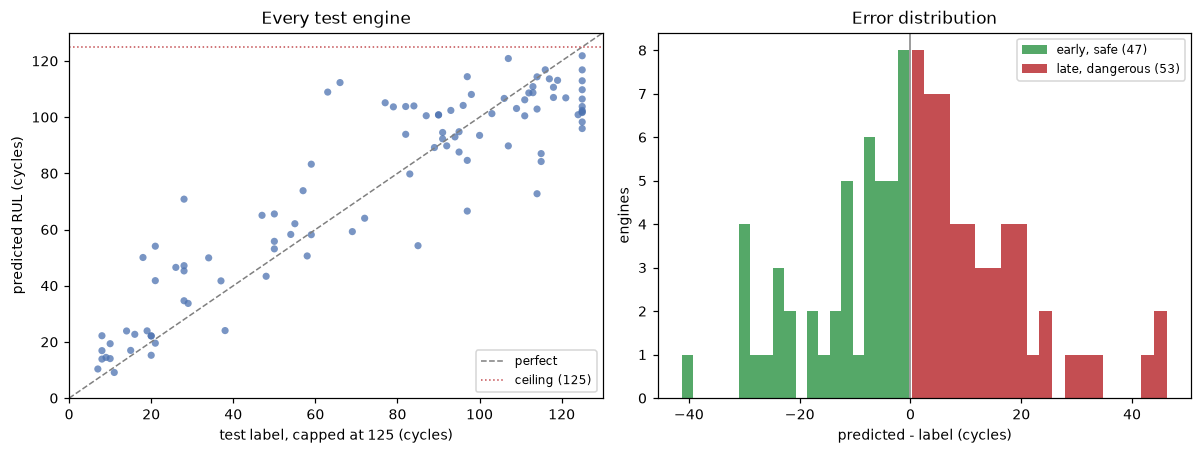

Nothing can sit above the dotted line at 125: the sigmoid output makes it
impossible. That is why assumption A-02 caps the test labels as well.

11 of the 100 test engines have more than 125 cycles left, so their
label is 125, below the life they truly had.


In [15]:
label = prepared.test.targets.astype(float)
guess = predict(model, prepared.test)
error = prediction_error(label, guess)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].scatter(label, guess, s=22, alpha=0.75, color="#4C72B0", edgecolor="none")
lims = [0, config.rul_max + 5]
axes[0].plot(lims, lims, color="grey", linestyle="--", linewidth=1, label="perfect")
axes[0].axhline(config.rul_max, color="#C44E52", linestyle=":", linewidth=1,
                label=f"ceiling ({config.rul_max})")
axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel(f"test label, capped at {config.rul_max} (cycles)"); axes[0].set_ylabel("predicted RUL (cycles)")
axes[0].set_title("Every test engine"); axes[0].legend(fontsize=8)

axes[1].hist(error[error < 0], bins=20, color="#55A868", label=f"early, safe ({int((error<0).sum())})")
axes[1].hist(error[error >= 0], bins=20, color="#C44E52", label=f"late, dangerous ({int((error>=0).sum())})")
axes[1].axvline(0, color="grey", linewidth=1)
axes[1].set_xlabel("predicted - label (cycles)"); axes[1].set_ylabel("engines")
axes[1].set_title("Error distribution"); axes[1].legend(fontsize=8)

fig.tight_layout(); plt.show()
print("Nothing can sit above the dotted line at 125: the sigmoid output makes it")
print("impossible. That is why assumption A-02 caps the test labels as well.")

# NASA's answer for each test engine, before any cap: a pandas Series of 100
# remaining lives, one per test engine, read from RUL_FD001.txt.
life = read_rul_file(data_dir / f"RUL_{config.subset}.txt")
above_cap = int((life > config.rul_max).sum())
print()
print(f"{above_cap} of the {len(life)} test engines have more than {config.rul_max} cycles left, so their")
print(f"label is {config.rul_max}, below the life they truly had.")

**Check.** No prediction may exceed the ceiling of 125, whatever the input.

In [16]:
assert guess.max() <= config.rul_max + 1e-6
print(f"OK  The largest prediction is {guess.max():.2f}, and the ceiling is {config.rul_max}.")

OK  The largest prediction is 121.85, and the ceiling is 125.


## 5. The sensor graph, put to the test

What the sensor graph lets this network see, and whether the paper's graph makes it predict any better than two others, have a folder of their own, `notebooks/graph/`: one notebook for each of three graphs — the paper's Table 3, every sensor joined to every other, and the 41 pairs of sensors whose readings move together most strongly — and a fourth that compares them. They read the stored five-seed runs instead of training, so every number they show names the commit that produced it.

- **What the paper's graph lets this network see**, including the pairs of sensors three graph layers cannot connect: `notebooks/graph/01_physics_fd001.ipynb`.
- **Whether the paper's graph beats the two others**, five seeds each, on the test engines and on the held-back engines: `notebooks/graph/04_comparison_fd001.ipynb`.

(Moved on 2026-10-02. Until then this section trained the two other graphs' networks here, for one seed, before reading the five-seed runs.)

## 6. The whole thing in one command

Steps 9, 10 and 11 are also what `scripts/train.py` does, once per seed, and that script is what produces the numbers this project reports. With five seeds it trains five networks — seeds 42 to 46, each with its own draw of held-back engines — scores each on the test engines, and writes the results to a new directory under `reports/`, named after the configuration, the commit and the time:

```bash
python scripts/train.py --config config/fd001.yaml --seeds 5
```

Its first seed is 42, the seed this notebook used, with the same settings, the same held-back engines and the same order of batches. So if the notebook and the script really do the same thing, **this notebook's run must be the first row of that script's results, number for number.** The next cell finds the most recent stored five-seed run of this configuration and checks exactly that. If the two ever disagree, the notebook and the script have drifted apart, or the stored run was made by code that trains differently, and the stored run should not be quoted until the command above has been run again.

`reports/` is not part of the repository, so a fresh copy of the project has no stored runs. The cell then says so and checks nothing.

(Corrected 2026-10-03: the cell did not compare the network's own settings, so a five-seed run stored on 2026-10-02 whose graph layers have offsets, a different network, was taken for this configuration and the check failed. It now requires Table 4's network, and the training settings of step 10, as well. Found when the notebook was run again that day.)

In [17]:
def describes_this_notebook(run: Path) -> bool:
    # The physics graph, five seeds, the split varying with the seed, early
    # stopping on, the step schedule, the last-cycle stage, Table 4's network
    # (its widths, and no offsets in the graph layers), this notebook's
    # training settings, and preprocessing settings identical to
    # config/fd001.yaml. A run from before a field was
    # recorded is skipped rather than guessed at.
    summary = json.loads((run / "summary.json").read_text(encoding="utf-8"))
    stored = yaml.safe_load((run / "preprocessing_config.yaml").read_text(encoding="utf-8"))
    ours = config.to_dict()
    return (
        summary.get("seeds") == 5
        and summary.get("split") == "varies_with_seed"
        and summary.get("early_stopping") is True
        and summary.get("lr_schedule") == "step"
        and summary.get("temporal_stage") == "last_cycle"
        and summary.get("model") == ModelConfig().to_dict()
        and all(summary.get("training", {}).get(key) == getattr(training, key)
                for key in ("epochs", "batch_size", "learning_rate",
                            "final_learning_rate", "early_stopping_patience"))
        and all(key in stored and stored[key] == value
                for key, value in ours.items() if key != "notes")
    )

reports = PROJECT_ROOT / "reports"
runs = [
    run for run in (sorted(reports.iterdir()) if reports.is_dir() else [])
    if all((run / name).is_file()
           for name in ("summary.json", "results.csv", "preprocessing_config.yaml"))
    and describes_this_notebook(run)
]
runs.sort(key=lambda run: json.loads((run / "summary.json").read_text(encoding="utf-8"))["finished_utc"])
stored_run = runs[-1] if runs else None

if stored_run is None:
    matches_script = None
    print("No stored five-seed run of this configuration in reports/, so nothing is checked.")
    print("Produce one with:  python scripts/train.py --config config/fd001.yaml --seeds 5")
else:
    summary = json.loads((stored_run / "summary.json").read_text(encoding="utf-8"))
    first = pd.read_csv(stored_run / "results.csv").set_index("seed").loc[training.seed]
    print(f"Stored run : {stored_run.name}")
    print(f"Commit     : {summary['commit']}")
    print(f"Finished   : {summary['finished_utc']} (UTC)\n")

    measures = (("rmse", "RMSE"), ("score", "NASA score"), ("r2", "R-squared"), ("asue", "ASUE"))
    display(pd.DataFrame(
        [{"": label, "this notebook, seed 42": result[key],
          f"stored run, seed {training.seed}": first[key]} for key, label in measures]
        + [{"": "best epoch", "this notebook, seed 42": history.best_epoch,
            f"stored run, seed {training.seed}": int(first["best_epoch"])}]
    ).set_index(""))

    matches_script = bool(
        all(np.isclose(result[key], first[key], rtol=1e-9, atol=1e-6) for key, _ in measures)
        and history.best_epoch == int(first["best_epoch"])
    )
    if matches_script:
        print("OK  This notebook's run is the first seed of the stored run, number for number.\n")
    else:
        print("DIFFERS  The stored run no longer describes the code this notebook ran.")
        print("         Run the command above again before quoting it.\n")

    print(f"The result, over all {summary['seeds']} seeds (mean +/- standard deviation):")
    for key, label in measures:
        print(f"  {label:12s} {summary['mean'][key]:9.3f} +/- {summary['std'][key]:.3f}")

Stored run : fd001_physics_row_cap_5seed_varsplit_cfgba82e3_f4f40ad_20261002T152416Z


Commit     : f4f40ad
Finished   : 20261002T152416Z (UTC)



,"this notebook, seed 42","stored run, seed 42"
,,
RMSE,16.694915,16.694915
NASA score,580.398364,580.398364
R-squared,0.826436,0.826436
ASUE,12.252574,12.252574
best epoch,51.000000,51.000000


OK  This notebook's run is the first seed of the stored run, number for number.

The result, over all 5 seeds (mean +/- standard deviation):
  RMSE            16.496 +/- 0.415
  NASA score     539.822 +/- 44.748
  R-squared        0.830 +/- 0.008
  ASUE            11.651 +/- 0.995


## 7. Final verification

Every claim this notebook makes, checked in one place. A reader who trusts nothing else should be able to run this cell.

In [18]:
checks: list[tuple[str, str, str]] = []

def check(description: str, condition: bool | None, detail: str = "") -> None:
    status = "SKIP" if condition is None else ("PASS" if condition else "FAIL")
    checks.append((description, status, detail))

# --- the data from notebook 01 ---
check("Settings are notebook 01's", not differ, "config/fd001.yaml")
check("Training and held-back engines are disjoint",
      set(prepared.train.units.tolist()).isdisjoint(prepared.validation.units.tolist()))
check("Exactly one example per test engine",
      len(prepared.test) == len(np.unique(prepared.test.units)), f"{len(prepared.test)} engines")

# --- step 9: the network ---
check("Parameter count: Table 4's weights plus the dense offsets",
      model.count_parameters() == weights + offsets == 61_729,
      f"{weights:,} + {offsets} = {model.count_parameters():,}")
check("Each sensor node carries one number (assumption A-07)",
      model.in_features == 1, f"{model.in_features} per node")
check("Mixing averages a sensor with its neighbours",
      abs(by_hand - by_matrix) < 1e-6, f"{sensor}, first test engine")

# --- step 10: training ---
kept_best = (abs(evaluate_model(model, prepared.validation)["rmse"]
                 - history.best_validation_rmse) < 1e-6
             if len(prepared.validation) else None)
check("Parameters kept are the best epoch's (assumption A-06)", kept_best, f"epoch {history.best_epoch}")

# --- step 11: scoring ---
check("Every test engine has a finite prediction",
      len(guess) == len(prepared.test) and bool(np.isfinite(guess).all()), f"{len(guess)} engines")
check("No prediction above the ceiling (assumption A-13)",
      guess.max() <= config.rul_max + 1e-6, f"largest {guess.max():.2f}")

# --- section 6: the script ---
check("This run is seed 42 of the stored five-seed run", matches_script,
      summary["commit"] if stored_run is not None else "no stored run in reports/")

# --- report ---
width = max(len(description) for description, _, _ in checks) + 2
print(f"{'CHECK':<{width}} RESULT   DETAIL")
print("-" * (width + 30))
for description, status, detail in checks:
    print(f"{description:<{width}} {status:<8} {detail}")

failed = [description for description, status, _ in checks if status == "FAIL"]
skipped = sum(status == "SKIP" for _, status, _ in checks)
print("-" * (width + 30))
if failed:
    raise AssertionError(f"{len(failed)} check(s) failed: {failed}")
print(f"All {len(checks) - skipped} checks passed"
      + (f"; {skipped} skipped, for the reason in its row." if skipped else "."))

CHECK                                                       RESULT   DETAIL
-----------------------------------------------------------------------------------------
Settings are notebook 01's                                  PASS     config/fd001.yaml
Training and held-back engines are disjoint                 PASS     
Exactly one example per test engine                         PASS     100 engines
Parameter count: Table 4's weights plus the dense offsets   PASS     61,600 + 129 = 61,729
Each sensor node carries one number (assumption A-07)       PASS     1 per node
Mixing averages a sensor with its neighbours                PASS     P15, first test engine
Parameters kept are the best epoch's (assumption A-06)      PASS     epoch 51
Every test engine has a finite prediction                   PASS     100 engines
No prediction above the ceiling (assumption A-13)           PASS     largest 121.85
This run is seed 42 of the stored five-seed run             PASS     f4f40ad
-------------

## 8. Summary and next steps

### What this notebook produced

Starting from notebook 01's examples and graph, it produced:

- **A network** with 61 729 parameters — the 61 600 of the five weight matrices the paper's Table 4 prints, and the 129 offsets its Equations 12 and 13 give the two dense layers — each sensor node carrying one number into the graph layers, and beside it the paper's own recurrent stage, built but not trained here.
- **One trained run**, seed 42, scored on the 100 test engines with the paper's four measures. It is the first of the five seeds behind this project's reported result, not a result on its own, and it compares only with the paper's **"ESTGNN w/o LSTM"** row.

(Corrected 2026-10-03: this list, step 9's check and the closing checklist said that the weight shapes Table 4 prints imply all 61 729 parameters; the shapes give 61 600, and the other 129 are the offsets of Equations 12 and 13. Step 9's check and the closing checklist were found by searching the repository for "61,729" in answering the audit of 2026-09-08 (`docs/audits/AUDIT_2026-09-08_response.md`); this list was found on 2026-10-03, by searching for the same wording.)

Unlike notebook 01, this notebook saves nothing. The networks this project explains are the ones `scripts/train.py` stores with the commit that trained them, and `notebooks/xai/` loads those.

### Decisions that were not read from the paper

| Decision | Value used | Written up as |
|---|---|---|
| Held-back engines | 20 % of the training engines, and the best epoch's parameters are kept | A-06 |
| What a sensor node carries | The last cycle of its window, one number per sensor | A-07 |
| The per-sensor recurrent stage | Built, but not the one trained here | A-11 |
| Bias in the graph layers | None, as Equations 8 to 10 print | A-12 |
| Scale of the target | Labels divided by 125 for training, predictions multiplied back | A-13 |
| Starting values of the graph and dense layers | The graph layers: random values from a range set by the layer's size, following Kipf & Welling (2017); the dense layers: PyTorch's own default | A-14 |
| Sign of the NASA score | The convention the paper's own text describes | A-15 |
| Denominator of R² | The observed values, not the predicted ones | A-16 |
| How the learning rate falls | One drop, by a factor of ten, at the halfway epoch | A-17 |
| Early stopping | After 20 epochs without improvement on the held-back engines | A-18 |
| How the graph is rescaled | Each row divided by its own total | A-21 |
| Size of the recurrent stage | One layer, hidden size 32, projected to one number per sensor | A-26 |
| Starting values of the recurrent stage | PyTorch's own: every number drawn evenly between −0.177 and +0.177 (one over the square root of 32), so each forget gate, the part that decides how much of the memory carried from the cycle before to keep, starts near one half | A-34 |

Full reasoning is in `docs/assumptions/`. Two to keep in mind: leaving out the recurrent stage decides which published row a number may be compared with, and keeping the best epoch's parameters decides most of what the recurrent stage appears to be worth.

(Corrected 2026-10-02: the starting-values row said that every parameter starts the way Kipf & Welling (2017) start theirs; only the graph layers do. The recurrent stage's starting values now have a row of their own.)

### What comes next

1. **Explain the trained network.** `notebooks/xai/` starts with the paper's own method, exact Shapley values, and follows one engine's whole life.
2. **Read what the sensor graph does.** `notebooks/graph/` shows three sensor graphs on the real data and compares their stored five-seed runs: without the recurrent stage, and, from runs stored at another commit by a study that changed one setting at a time (finding F-19), with it. What remains open is that comparison with both halves trained from one committed state of the code, and under the paper's own procedure, which holds no engines back and keeps the parameters after the last pass, and which changes what the recurrent stage is worth (finding F-16). (Corrected 2026-10-02: this item first asked for the recurrent-stage comparison as though no run of it were stored; a review the same day found the study's runs.)
3. **Explain edges and subgraphs, not only sensors.** Every explanation so far assigns credit to a sensor. Which *connections* in the graph a prediction depended on is the question this thesis addresses and the paper does not.

### What this notebook is not

It is not a reproduction of the paper. The recurrent stage is not trained, the choices the paper does not specify are recorded in `docs/assumptions/`, and two of the paper's printed formulas could not be used as written: the sign of its score function and the denominator of its R-squared. What it is: a complete, documented implementation of everything the paper specifies for this network, measured against the row of its own table that describes this configuration.

### References

- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735-1780.
- Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. *ICLR*.
- Saxena, A., et al. (2008). Damage propagation modeling for aircraft engine run-to-failure simulation. *PHM 2008*.
- Wen, J.-R., et al. (2026). Explainable spatiotemporal graph neutral network with dynamic SHAP enhancement. *Aerospace Science and Technology*, 168, 110875.

Full citations, with a note on what each is used for, are in `docs/REFERENCES.md`.